<a href="https://colab.research.google.com/github/sankeawthong/Project-1-Lita-Chatbot/blob/main/Lab11_PCA_Clustering_Evaluation%20(Assignment).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11 — What Makes a Wine a Wine?

**Machine Learning (3 credits, 2-2-5) · Week 11 · School of Information Technology**

| | |
|---|---|
| **Time budget** | ~2 hours (in-lab) |
| **Learning objectives** | 1. Reduce 13 features with PCA and decide how many components to keep — 2. Read loadings and explain why scaling comes first — 3. Score clusterings without labels using silhouette, Davies–Bouldin and Calinski–Harabasz, and choose K — 4. Build a scaler → PCA → K-Means pipeline and compare clusterings fairly — 5. Use t-SNE as a picture, and know its limits |
| **Dataset** | 178 wines · 13 chemical measurements (`load_wine`, built into scikit-learn) · 1,797 handwritten digits for the t-SNE demo (`load_digits`) |
| **Grading** | Exercises 1–6 + AI-usage disclosure · self-checks give instant feedback |

> **The story.** A wine importer receives laboratory measurements for 178 wines — alcohol, acidity, colour, phenols and so on — but the labels showing which grape cultivar each wine came from were lost. Can the chemistry alone sort the wines into groups? With 13 features we cannot even plot the data, so today we first **see** it (PCA) and then **score** the groups we find (three metrics, no labels needed).
>
> The true cultivar is kept aside in `_cultivar`. It is used **only** to check our results at the end — never to fit anything.

**First:** File → Save a copy in Drive, rename to `Lab11_<your_student_id>`.

---
## Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

RNG_SEED = 42
PAL = ["#15807E", "#E8912D", "#1B2A41", "#C4553B", "#7B9EB3", "#9C6BA8", "#6BA368", "#C9A227", "#8C564B", "#E377C2"]
print("Setup complete ✔")

Setup complete ✔


---
## Part 1 · Meet the data — and why we can't just plot it

Thirteen measurements per wine. Look at the ranges: proline runs into the hundreds and thousands, hue stays near 1. Any method that uses distances or variance (K-Means, silhouette, PCA) will be ruled by proline unless we scale.

In [2]:
wine = load_wine(as_frame=True)
X = wine.data                      # 178 × 13
_cultivar = wine.target            # kept aside — ONLY for checking at the end
print(X.shape)
X.describe().loc[["mean", "std", "min", "max"]].T.round(2)

(178, 13)


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


pairs of features with |r| > 0.6: 6 of 78
strongest correlation: 0.865


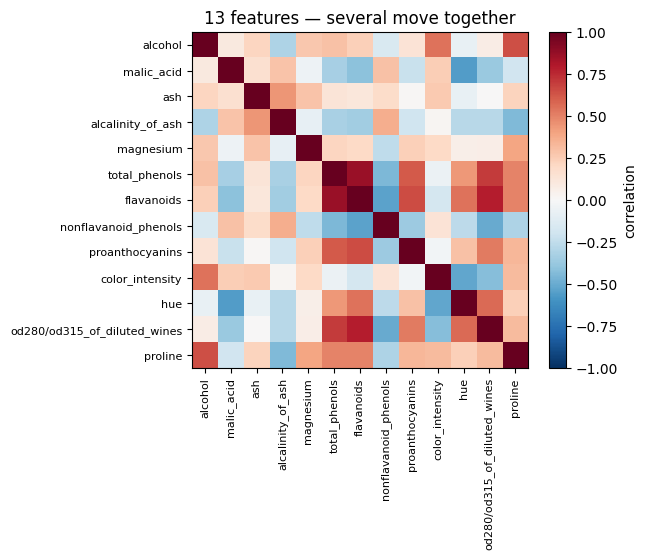

In [3]:
# How much do the features repeat each other?
corr = X.corr().abs().to_numpy().copy()
np.fill_diagonal(corr, 0)
print(f"pairs of features with |r| > 0.6: {int((corr > 0.6).sum() / 2)} of {13*12//2}")
print(f"strongest correlation: {corr.max():.3f}")

plt.figure(figsize=(6.5, 5.5))
plt.imshow(X.corr(), cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(13), X.columns, rotation=90, fontsize=8); plt.yticks(range(13), X.columns, fontsize=8)
plt.colorbar(label="correlation"); plt.title("13 features — several move together"); plt.tight_layout(); plt.show()

**What to notice:** flavanoids, total phenols and OD280 move together — they are, roughly, three measurements of one thing. That redundancy is what PCA compresses.

---
## Part 2 · PCA — how much does each component keep?

Standardise first, then fit PCA with **all** components so we can see how the variance is shared out.

In [4]:
scaler = StandardScaler()
Z = scaler.fit_transform(X)                 # 178 × 13, every feature mean 0, std 1

pca = PCA(random_state=RNG_SEED).fit(Z)
ratio = pca.explained_variance_ratio_
cum = np.cumsum(ratio)
pd.DataFrame({"component": [f"PC{i+1}" for i in range(13)],
              "variance %": (ratio * 100).round(1),
              "cumulative %": (cum * 100).round(1)}).set_index("component").T

component,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
variance %,36.2,19.2,11.1,7.1,6.6,4.9,4.2,2.7,2.2,1.9,1.7,1.3,0.8
cumulative %,36.2,55.4,66.5,73.6,80.2,85.1,89.3,92.0,94.2,96.2,97.9,99.2,100.0


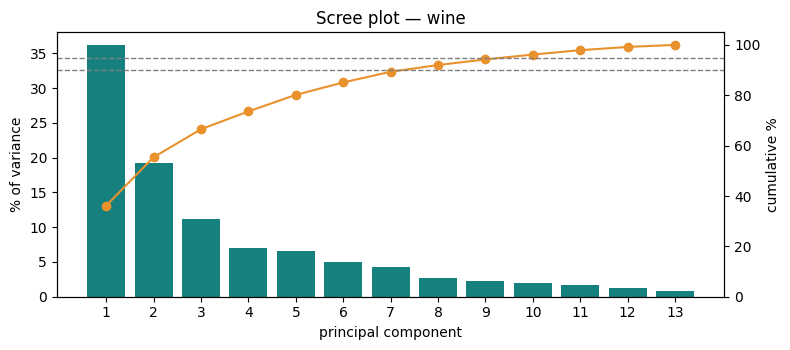

PC1 + PC2 keep 55.4% · components needed for 90%: 8


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(1, 14), ratio * 100, color="#15807E", label="each component")
ax2 = ax.twinx(); ax2.plot(range(1, 14), cum * 100, "-o", color="#E8912D", label="cumulative")
for t in (90, 95): ax2.axhline(t, ls="--", lw=1, color="grey")
ax.set_xlabel("principal component"); ax.set_ylabel("% of variance"); ax2.set_ylabel("cumulative %"); ax2.set_ylim(0, 105)
ax.set_xticks(range(1, 14)); plt.title("Scree plot — wine"); plt.tight_layout(); plt.show()

k90 = int(np.searchsorted(cum, 0.90) + 1)
print(f"PC1 + PC2 keep {cum[1]*100:.1f}% · components needed for 90%: {k90}")

**Reading it:** PC1 keeps about a third of the variance, PC2 another fifth. Two components already hold more than half of what 13 measurements say — enough to draw a useful picture.

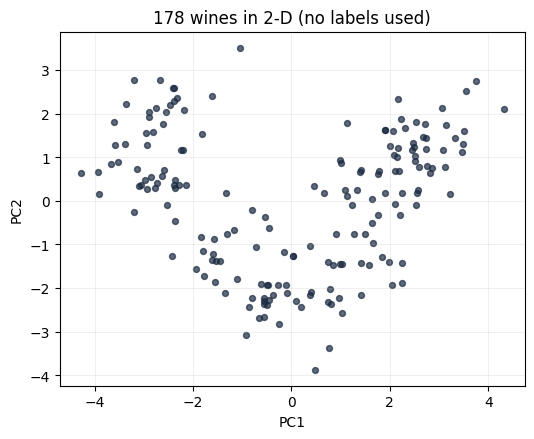

In [7]:
Z2 = PCA(n_components=2, random_state=RNG_SEED).fit_transform(Z)
plt.figure(figsize=(6, 4.6))
plt.scatter(Z2[:, 0], Z2[:, 1], s=18, color="#1B2A41", alpha=0.7)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("178 wines in 2-D (no labels used)"); plt.grid(alpha=0.2); plt.show()

Without any labels you can already see three loose groups. Hold that thought for Part 4.

---
## Part 3 · What do PC1 and PC2 mean? And why scale first?

A component is a recipe: a weight for each original feature (`pca.components_`). Large |weight| = that feature matters.

In [8]:
loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])
print("PC1 — largest |loadings|"); print(loadings["PC1"].reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(5).round(3), "\n")
print("PC2 — largest |loadings|"); print(loadings["PC2"].reindex(loadings["PC2"].abs().sort_values(ascending=False).index).head(5).round(3))

PC1 — largest |loadings|
flavanoids                      0.423
total_phenols                   0.395
od280/od315_of_diluted_wines    0.376
proanthocyanins                 0.313
nonflavanoid_phenols           -0.299
Name: PC1, dtype: float64 

PC2 — largest |loadings|
color_intensity    0.530
alcohol            0.484
proline            0.365
ash                0.316
magnesium          0.300
Name: PC2, dtype: float64


**Interpretation:** PC1 is a *phenols* axis (flavanoids, total phenols, OD280 high; non-flavanoid phenols low). PC2 is an *intensity* axis (colour intensity, alcohol, proline). A chemist could check these names — that is how you explain a component without the word "eigenvector".

*(The sign of a whole component can flip between library versions; the meaning does not.)*

Now the same PCA **without** scaling:

In [9]:
pca_raw = PCA(random_state=RNG_SEED).fit(X)
top = X.columns[np.argmax(np.abs(pca_raw.components_[0]))]
print(f"raw PC1 keeps {pca_raw.explained_variance_ratio_[0]*100:.2f}% of the variance — dominated by '{top}'")
print(f"proline variance: {X['proline'].var():,.0f}   ·   hue variance: {X['hue'].var():.3f}")

raw PC1 keeps 99.81% of the variance — dominated by 'proline'
proline variance: 99,167   ·   hue variance: 0.052


Raw PCA is not summarising the wines — it is just finding the feature with the biggest numbers. **Scale first**, unless every feature already shares one unit (for example, pixel intensities).

---
## Part 4 · Scoring clusters without labels — three metrics

K-Means on the 13 scaled features for K = 2 … 8. For each K, three internal metrics:

| metric | better is | what it compares |
|---|---|---|
| silhouette | higher (−1 … 1) | for every point: nearest other cluster vs own cluster |
| Davies–Bouldin | **lower** (0 … ∞) | each cluster's spread vs its most similar neighbour |
| Calinski–Harabasz | higher (0 … ∞) | spread between centroids vs spread within clusters |

In [10]:
rows = []
for k in range(2, 9):
    lab = KMeans(n_clusters=k, n_init=10, random_state=RNG_SEED).fit_predict(Z)
    rows.append({"K": k,
                 "silhouette ↑": silhouette_score(Z, lab),
                 "Davies–Bouldin ↓": davies_bouldin_score(Z, lab),
                 "Calinski–Harabasz ↑": calinski_harabasz_score(Z, lab)})
metrics = pd.DataFrame(rows).set_index("K").round(3)
metrics

,silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑
K,,,
2,0.259,1.526,69.523
3,0.285,1.389,70.940
4,0.260,1.797,56.181
5,0.202,1.808,46.952
6,0.237,1.554,41.701
7,0.204,1.661,38.686
8,0.157,1.741,35.805


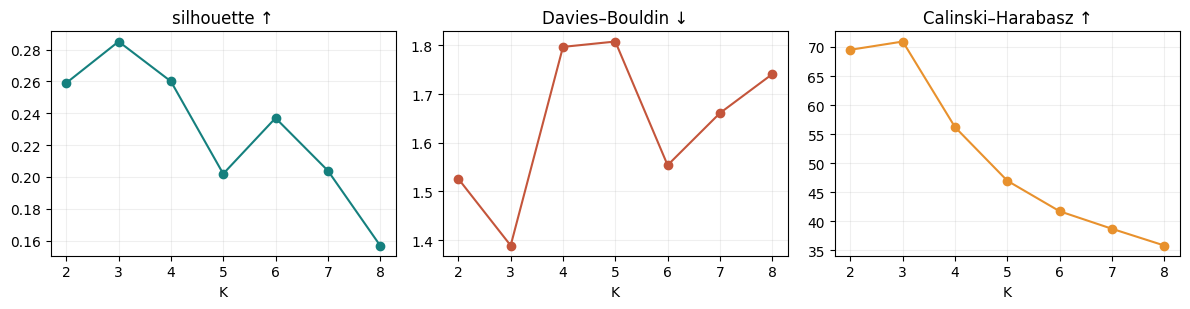

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, c in zip(axs, metrics.columns, ["#15807E", "#C4553B", "#E8912D"]):
    ax.plot(metrics.index, metrics[col], "-o", color=c); ax.set_title(col); ax.set_xlabel("K"); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

All three point the same way here — a rare and happy case. Where they disagree, look at the PCA picture and decide by purpose (lecture, Part 2).

**A per-point view.** The silhouette *score* is an average; `silhouette_samples` shows which wines are badly placed.

wines with negative silhouette: 7 of 178


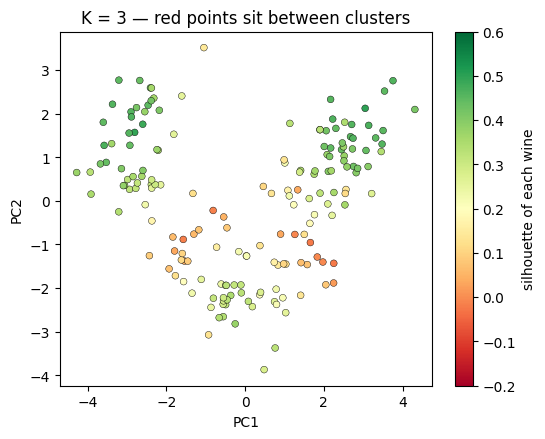

In [12]:
lab3 = KMeans(n_clusters=3, n_init=10, random_state=RNG_SEED).fit_predict(Z)
s = silhouette_samples(Z, lab3)
print(f"wines with negative silhouette: {(s < 0).sum()} of {len(s)}")
plt.figure(figsize=(6, 4.6))
sc = plt.scatter(Z2[:, 0], Z2[:, 1], c=s, cmap="RdYlGn", vmin=-0.2, vmax=0.6, s=24, edgecolor="k", linewidth=0.3)
plt.colorbar(sc, label="silhouette of each wine"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("K = 3 — red points sit between clusters"); plt.show()

---
## Part 5 · Scale → PCA → cluster, in one pipeline

`make_pipeline` chains the steps, so the scaler and PCA are fitted inside the pipeline — no leakage if you later split the data. `pipe[:-1].transform(X)` gives the data in the space the clusters were found in.

In [14]:
pipe = make_pipeline(StandardScaler(),
                     PCA(n_components=0.90, random_state=RNG_SEED),
                     KMeans(n_clusters=3, n_init=10, random_state=RNG_SEED))
lab_pipe = pipe.fit_predict(X)
S = pipe[:-1].transform(X)
print(f"PCA kept {S.shape[1]} components for 90% of the variance")
print(f"silhouette in PCA space : {silhouette_score(S, lab_pipe):.3f}")
print(f"silhouette in 13-D space: {silhouette_score(Z, lab_pipe):.3f}")
print(f"ARI vs cultivar (check) : {adjusted_rand_score(_cultivar, lab_pipe):.3f}")

PCA kept 8 components for 90% of the variance
silhouette in PCA space : 0.315
silhouette in 13-D space: 0.285
ARI vs cultivar (check) : 0.897


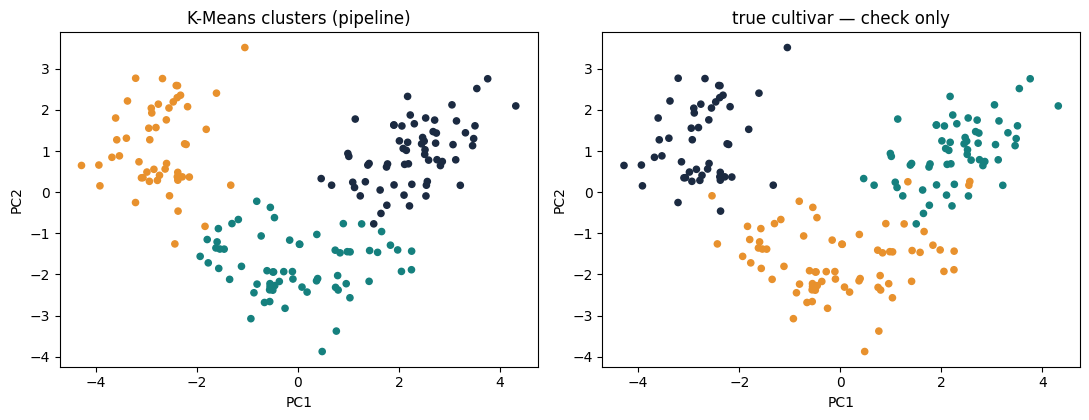

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, lab, t in [(axs[0], lab_pipe, "K-Means clusters (pipeline)"), (axs[1], _cultivar, "true cultivar — check only")]:
    ax.scatter(Z2[:, 0], Z2[:, 1], c=[PAL[i] for i in lab], s=20); ax.set_title(t); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Same clusters, different scores.** The silhouette looks better in PCA space only because fewer dimensions make every cluster look tighter. Compare metrics only when they are computed **in the same space**.

---
## Part 6 · t-SNE — a picture tool (demonstration only)

Digits: 64 pixel values per image. PCA is a rotation (honest distances, overlapping digits); t-SNE keeps neighbourhoods (clean islands, but distances between islands mean nothing). t-SNE's derivation is **not** examinable — its five rules are.

t-SNE took 18.9 s


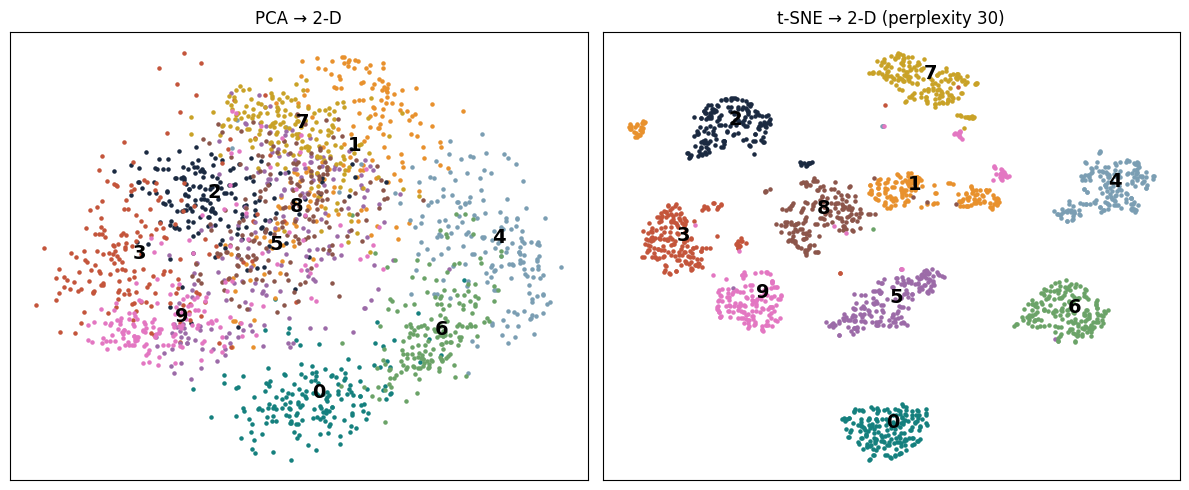

In [17]:
digits = load_digits(); Xd, _digit = digits.data, digits.target   # _digit used only to colour the picture
Pd = PCA(n_components=2, random_state=RNG_SEED).fit_transform(Xd)
t0 = time.perf_counter()
Td = TSNE(n_components=2, perplexity=30, init="pca", random_state=RNG_SEED).fit_transform(Xd)
print(f"t-SNE took {time.perf_counter() - t0:.1f} s")

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, E, t in [(axs[0], Pd, "PCA → 2-D"), (axs[1], Td, "t-SNE → 2-D (perplexity 30)")]:
    for d in range(10):
        m = _digit == d
        ax.scatter(E[m, 0], E[m, 1], s=5, color=PAL[d]); ax.text(*np.median(E[m], axis=0), str(d), fontsize=14, weight="bold")
    ax.set_title(t); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**The five rules:** (1) distances between islands mean nothing; (2) island sizes mean nothing; (3) a different seed or perplexity gives a different picture — state your settings; (4) there is no `transform` for new points; (5) do not cluster or model on the t-SNE output — use it to **look**.

---
# Exercises (graded)

Fill in every `...`. Run the self-check cell after each exercise.

### Exercise 1 · Davies–Bouldin and Calinski–Harabasz from the formula

Implement both metrics with numpy, then check them on the lecture example (points 1, 3 | 9, 11 → DB = 0.25, CH = 32) and on the wine clustering against scikit-learn.

- DB: for each cluster, spread $S_i$ = mean distance of its points to its centroid; $R_{ij} = (S_i + S_j)/M_{ij}$ with $M_{ij}$ the distance between centroids; DB = mean over clusters of the largest $R_{ij}$.
- CH: $B = \sum_i n_i\,\lVert c_i - \bar c\rVert^2$, $W = \sum \lVert x - c_{own}\rVert^2$, $CH = \dfrac{B/(k-1)}{W/(n-k)}$.

In [ ]:
def my_davies_bouldin(X, labels):
    X = np.asarray(X, float); labels = np.asarray(labels)
    ks = np.unique(labels)
    cent = np.array([X[labels == k].mean(axis=0) for k in ks])
    S = np.array([...  for i, k in enumerate(ks)])          # mean distance of cluster k's points to its centroid
    worst = []
    for i in range(len(ks)):
        R = [(S[i] + S[j]) / np.linalg.norm(cent[i] - cent[j]) for j in range(len(ks)) if j != i]
        worst.append(...)                                    # the largest R for cluster i
    return float(np.mean(worst))

def my_calinski_harabasz(X, labels):
    X = np.asarray(X, float); labels = np.asarray(labels)
    ks = np.unique(labels); n, k = len(X), len(ks)
    overall = X.mean(axis=0)
    B = sum(...  for c in ks)                                # n_i * ||c_i − overall||²
    W = sum(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum() for c in ks)
    return float((B / (k - 1)) / (...))

pts = np.array([[1.], [3.], [9.], [11.]]); lab_pts = [0, 0, 1, 1]
db_small, ch_small = my_davies_bouldin(pts, lab_pts), my_calinski_harabasz(pts, lab_pts)
db_wine, ch_wine = my_davies_bouldin(Z, lab3), my_calinski_harabasz(Z, lab3)
print(f"small: DB {db_small:.3f}  CH {ch_small:.1f}   ·   wine: DB {db_wine:.3f}  CH {ch_wine:.1f}")

In [ ]:
# ✅ Self-check — Exercise 1
assert abs(db_small - 0.25) < 1e-9 and abs(ch_small - 32) < 1e-9, "Check the lecture example first: DB should be 0.25 and CH 32."
assert abs(db_wine - davies_bouldin_score(Z, lab3)) < 1e-6, "Your DB differs from scikit-learn on the wine data."
assert abs(ch_wine - calinski_harabasz_score(Z, lab3)) < 1e-6, "Your CH differs from scikit-learn on the wine data."
print("Exercise 1 ✔  — your formulas match scikit-learn")

### Exercise 2 · PCA by hand with numpy

The four centred points from the lecture: A (2, 1), B (1, 2), C (−1, −2), D (−2, −1). Compute the sum-of-squares matrix $S = P^\top P$, its eigenvalues and eigenvectors (`np.linalg.eigh` returns them **smallest first**), the share of variance PC1 keeps, and A's projection onto PC1.

In [ ]:
P = np.array([[2., 1.], [1., 2.], [-1., -2.], [-2., -1.]])
S_mat = ...                                  # 2 × 2
vals, vecs = np.linalg.eigh(S_mat)           # ascending order
pc1 = vecs[:, ...]                           # eigenvector of the LARGEST eigenvalue
share_pc1 = ...                              # largest eigenvalue / sum of eigenvalues
proj_A = ...                                 # A · pc1
print(S_mat, "\neigenvalues:", vals, "\nPC1:", pc1.round(3), f"\nshare {share_pc1:.2f} · A on PC1 {proj_A:.3f}")

In [ ]:
# ✅ Self-check — Exercise 2
assert np.allclose(S_mat, [[10, 8], [8, 10]]), "S should be [[10, 8], [8, 10]] — use P.T @ P."
assert np.allclose(sorted(vals), [2, 18]), "Eigenvalues should be 2 and 18 (a − b and a + b)."
assert abs(share_pc1 - 0.9) < 1e-9, "PC1 should keep 18 / 20 = 90%."
assert abs(abs(proj_A) - 3 / np.sqrt(2)) < 1e-9, "A projects to ±3/√2 ≈ ±2.121 (the sign depends on the eigenvector's direction)."
assert np.isclose(PCA().fit(P).explained_variance_ratio_[0], share_pc1), "scikit-learn should agree with your share."
print("Exercise 2 ✔  — 90% on PC1, exactly as on the slide")

### Exercise 3 · How many components for 95%?

Use the cumulative share `cum` from Part 2. Then fit `PCA(n_components=0.95)` on `Z` and confirm it keeps the same number.

In [ ]:
k95 = ...                                      # smallest k with cum[k-1] >= 0.95
pca95 = PCA(n_components=0.95, random_state=RNG_SEED).fit(Z)
print(f"k for 95%: {k95} · scikit-learn chose {pca95.n_components_} · variance kept {pca95.explained_variance_ratio_.sum():.3f}")

In [ ]:
# ✅ Self-check — Exercise 3
assert k95 == pca95.n_components_, "Your k should match what PCA(n_components=0.95) chose."
assert cum[k95 - 1] >= 0.95 and cum[k95 - 2] < 0.95, "k95 must be the SMALLEST k reaching 95%."
print(f"Exercise 3 ✔  — 13 features → {k95} components keep 95%")

### Exercise 4 · Choose K with three metrics

From the `metrics` table in Part 4, find the best K **according to each metric** (mind the directions), then write your choice.

In [ ]:
best_sil = int(metrics["silhouette ↑"].idxmax())
best_db  = ...                                  # Davies–Bouldin: LOWER is better
best_ch  = ...
print(f"silhouette → K = {best_sil} · Davies–Bouldin → K = {best_db} · Calinski–Harabasz → K = {best_ch}")
my_K = ...                                      # your choice

In [ ]:
# ✅ Self-check — Exercise 4
assert best_db == int(metrics["Davies–Bouldin ↓"].idxmin()), "Davies–Bouldin: take the K with the LOWEST value."
assert best_ch == int(metrics["Calinski–Harabasz ↑"].idxmax()), "Calinski–Harabasz: take the K with the HIGHEST value."
assert my_K == 3, "All three metrics agree on one K — which one?"
print(f"Exercise 4 ✔  — all three choose K = 3 (ARI vs cultivar, check only: {adjusted_rand_score(_cultivar, lab3):.3f})")

✍️ **In one or two sentences:** would you still choose K = 3 if the importer said they can only run two marketing campaigns? What would you report?

*(write here)*

### Exercise 5 · Raw vs PCA-2, measured fairly

Cluster with K = 3 in two spaces: the 13 scaled features (`Z`) and the first two PCA components (`Z2`). Compute each silhouette **in its own space**, then compute both **in the same 13-D space** `Z`, and the ARI (check only).

In [ ]:
lab_raw = KMeans(n_clusters=3, n_init=10, random_state=RNG_SEED).fit_predict(Z)
lab_p2  = KMeans(n_clusters=3, n_init=10, random_state=RNG_SEED).fit_predict(Z2)

sil_raw_own = silhouette_score(Z, lab_raw)
sil_p2_own  = ...                              # silhouette of lab_p2 measured in Z2
sil_p2_in_Z = ...                              # silhouette of lab_p2 measured in Z
ari_raw, ari_p2 = adjusted_rand_score(_cultivar, lab_raw), ...
print(f"own space : raw {sil_raw_own:.3f}  vs  PCA-2 {sil_p2_own:.3f}")
print(f"same space: raw {sil_raw_own:.3f}  vs  PCA-2 {sil_p2_in_Z:.3f}")
print(f"ARI check : raw {ari_raw:.3f}  vs  PCA-2 {ari_p2:.3f}")

In [ ]:
# ✅ Self-check — Exercise 5
assert abs(sil_p2_own - silhouette_score(Z2, lab_p2)) < 1e-9, "sil_p2_own must be computed in Z2."
assert abs(sil_p2_in_Z - silhouette_score(Z, lab_p2)) < 1e-9, "sil_p2_in_Z must be computed in Z."
assert sil_p2_own > sil_raw_own + 0.2 and abs(sil_p2_in_Z - sil_raw_own) < 0.02, "Look again at which space each score was computed in."
print("Exercise 5 ✔  — in its own space PCA-2 looks far better; in the same space, the two clusterings are almost identical")

✍️ **In two sentences:** a classmate says 'PCA-2 doubled the silhouette, so it found better clusters'. What is wrong with that claim?

*(write here)*

### Exercise 6 · Open-ended (choose any two of a–c, plus d)

**(a) Digits.** Cluster the 64-pixel digits with `KMeans(n_clusters=10)` on the raw pixels and on PCA with 90% variance. Compare ARI (check only) and fit time. Does PCA help? (No scaling needed — every pixel shares one unit.)

**(b) DBSCAN on the wine PCA-2 space.** Choose `min_samples=4`, draw a k-distance plot, try a few ε values, and report the number of clusters, the noise count and the silhouette **of the non-noise points**. Does DBSCAN suit this data? Why or why not?

**(c) Your choice.** Pick another `n_components` (e.g. 3 or 5) for the pipeline in Part 5 and compare it fairly with the 13-D result.

**(d) Write-up (required, at least 3 sentences).** What did PCA buy you on the wine data, and what would you put in a report to the importer?

In [ ]:
# (a), (b) or (c) — your code here
...

✍️ **(d) Write-up:**

*(write here — at least 3 sentences)*

---
## AI-usage disclosure (required)

Did you use an AI assistant (ChatGPT, Claude, Copilot, …) for any part of this lab? If yes: which tool, for which exercise, and what did you change in what it gave you? If no, write "No AI used".

*(write here)*

---
## Submitting
1. Kernel → Restart & Run All — no errors, every self-check ✔.
2. File → Download → `.ipynb`.
3. Upload `Lab11_<your_student_id>.ipynb` to the Lab 11 assignment on **MS Teams**.